<a href="https://colab.research.google.com/github/242236/machine-learning-titanic/blob/main/Evaluacion_Unidad_2_Machine_Learning_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación Unidad 2 – Machine Learning

## Aprendizaje supervisado aplicado al dataset Titanic

**Asignatura:** Machine Learning  
**Estudiante:** Carolina Cid Jara  
**Carrera:** Ingeniería Civil Industrial  
**Institución:** Universidad Mayor  
**Docente:** Franco Mansilla  
**Fecha:** Septiembre 2026

# Introducción

Esta evaluación continúa el trabajo desarrollado en la Unidad 1 con el dataset Titanic. En esa etapa se realizó la exploración, limpieza, tratamiento de valores faltantes y división de los datos en conjuntos de entrenamiento, validación y prueba.

En la Unidad 2 se aplican modelos de **aprendizaje supervisado** para resolver un problema de **clasificación binaria**, donde la variable objetivo `Survived` indica si un pasajero sobrevivió (`1`) o no sobrevivió (`0`).

Se entrenarán cuatro alternativas: un modelo con penalización L2, Random Forest, XGBoost y una red neuronal simple. Posteriormente se compararán mediante Accuracy, Precision, Recall, F1-Score, AUC y KS, se aplicará un método de optimización de hiperparámetros y se seleccionará un modelo final.

# Preparación de los datos heredada de la Unidad 1

Se mantiene la misma lógica utilizada en la evaluación anterior: se imputan los valores faltantes de `Age` con la mediana, `Embarked` con la categoría más frecuente y se elimina `Cabin`.

Para que los modelos sean simples y fáciles de explicar, se trabajará con las variables:

- `Pclass`
- `Sex`
- `Age`
- `SibSp`
- `Parch`
- `Fare`
- `Embarked`

Se excluyen identificadores y variables de alta cardinalidad como `PassengerId`, `Name` y `Ticket`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve
)

from xgboost import XGBClassifier

In [3]:
# Cargar los datos
datos = pd.read_csv("train.csv")

# Limpieza utilizada en la Unidad 1
datos["Age"] = datos["Age"].fillna(datos["Age"].median())
datos["Embarked"] = datos["Embarked"].fillna("S")
datos = datos.drop(columns=["Cabin"])

datos.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [4]:
# Separar variable objetivo y variables predictoras
X = datos.drop(columns=["Survived"])
y = datos["Survived"]

# Mantener la división 70% / 15% / 15% utilizada en la Unidad 1
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("Entrenamiento:", len(X_train))
print("Validación:", len(X_val))
print("Prueba:", len(X_test))

Entrenamiento: 623
Validación: 134
Prueba: 134


In [5]:
# Variables que usaremos en los modelos
variables = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X_train = X_train[variables]
X_val = X_val[variables]
X_test = X_test[variables]

variables_numericas = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
variables_categoricas = ["Sex", "Embarked"]

# Preparación automática:
# - estandariza variables numéricas
# - convierte variables categóricas en columnas 0/1
preprocesador = ColumnTransformer([
    ("numericas", StandardScaler(), variables_numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), variables_categoricas)
])

# Punto 1. Entrenamiento de diferentes modelos

La variable objetivo `Survived` es binaria, por lo que corresponde a un problema de clasificación.

Se entrenan los cuatro modelos solicitados:

1. **Modelo penalizado:** regresión logística con penalización L2. Se utiliza L2 porque corresponde al principio de Ridge aplicado a un problema de clasificación.
2. **Random Forest:** ensamble de múltiples árboles entrenados con bagging.
3. **XGBoost:** ensamble secuencial donde cada nuevo árbol busca corregir errores previos.
4. **Red neuronal simple:** perceptrón multicapa con una capa oculta de 10 neuronas.

## 1.1 Modelo penalizado L2

In [6]:
modelo_ridge = Pipeline([
    ("preparacion", preprocesador),
    ("modelo", LogisticRegression(
        penalty="l2",
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])

modelo_ridge.fit(X_train, y_train)
print("Modelo penalizado L2 entrenado correctamente.")

Modelo penalizado L2 entrenado correctamente.


## 1.2 Random Forest

In [7]:
modelo_rf = Pipeline([
    ("preparacion", preprocesador),
    ("modelo", RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    ))
])

modelo_rf.fit(X_train, y_train)
print("Random Forest entrenado correctamente.")

Random Forest entrenado correctamente.


## 1.3 XGBoost

In [ ]:
modelo_xgb = Pipeline([
    ("preparacion", preprocesador),
    ("modelo", XGBClassifier(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    ))
])

modelo_xgb.fit(X_train, y_train)
print("XGBoost entrenado correctamente.")

XGBoost entrenado correctamente.


## 1.4 Red neuronal simple

In [8]:
modelo_red = Pipeline([
    ("preparacion", preprocesador),
    ("modelo", MLPClassifier(
        hidden_layer_sizes=(10,),
        activation="relu",
        max_iter=1000,
        early_stopping=True,
        random_state=42
    ))
])

modelo_red.fit(X_train, y_train)
print("Red neuronal simple entrenada correctamente.")

Red neuronal simple entrenada correctamente.


# Punto 2. Métricas de desempeño

Para clasificación binaria se utilizarán:

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** de los casos predichos como sobrevivientes, cuántos realmente sobrevivieron.
- **Recall:** de los pasajeros que realmente sobrevivieron, cuántos fueron detectados por el modelo.
- **F1-Score:** equilibrio entre Precision y Recall.
- **AUC:** capacidad del modelo para discriminar entre sobrevivientes y no sobrevivientes en distintos umbrales.
- **KS:** máxima separación entre las clases positiva y negativa.

Las métricas se calculan en **entrenamiento y validación**, tal como solicita la evaluación.

In [9]:
def calcular_ks(y_real, probabilidades):
    fpr, tpr, _ = roc_curve(y_real, probabilidades)
    return np.max(tpr - fpr)

def evaluar_modelo(nombre, modelo, X_train, y_train, X_val, y_val):
    resultados = []

    for muestra, X_datos, y_datos in [
        ("Entrenamiento", X_train, y_train),
        ("Validación", X_val, y_val)
    ]:
        pred = modelo.predict(X_datos)
        prob = modelo.predict_proba(X_datos)[:, 1]

        resultados.append({
            "Modelo": nombre,
            "Muestra": muestra,
            "Accuracy": accuracy_score(y_datos, pred),
            "Precision": precision_score(y_datos, pred, zero_division=0),
            "Recall": recall_score(y_datos, pred, zero_division=0),
            "F1-Score": f1_score(y_datos, pred, zero_division=0),
            "AUC": roc_auc_score(y_datos, prob),
            "KS": calcular_ks(y_datos, prob)
        })

    return resultados

In [12]:
modelos = {
    "Ridge (Logística L2)": modelo_ridge,
    "Random Forest": modelo_rf,
    "XGBoost": modelo_xgb,
    "Red neuronal simple": modelo_red
}

resultados = []

for nombre, modelo in modelos.items():
    resultados.extend(
        evaluar_modelo(nombre, modelo, X_train, y_train, X_val, y_val)
    )

tabla_metricas = pd.DataFrame(resultados)
tabla_metricas.round(3)

,Modelo,Muestra,Accuracy,Precision,Recall,F1-Score,AUC,KS
0,Ridge (Logística L2),Entrenamiento,0.796,0.745,0.684,0.713,0.845,0.572
1,Ridge (Logística L2),Validación,0.821,0.870,0.734,0.797,0.909,0.693
2,Random Forest,Entrenamiento,0.872,0.904,0.732,0.809,0.913,0.700
3,Random Forest,Validación,0.813,0.882,0.703,0.783,0.926,0.753
4,XGBoost,Entrenamiento,0.897,0.933,0.779,0.849,0.938,0.759
5,XGBoost,Validación,0.828,0.936,0.688,0.793,0.912,0.701
6,Red neuronal simple,Entrenamiento,0.628,0.499,0.801,0.615,0.712,0.415
7,Red neuronal simple,Validación,0.701,0.646,0.828,0.726,0.732,0.507


In [11]:
modelo_xgb = Pipeline([
    ("preparacion", preprocesador),
    ("modelo", XGBClassifier(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    ))
])

modelo_xgb.fit(X_train, y_train)
print("XGBoost entrenado correctamente.")

XGBoost entrenado correctamente.


## Comparación en validación

Para seleccionar el modelo final se dará especial importancia al **AUC**, porque mide la capacidad general de discriminación entre sobrevivientes y no sobrevivientes sin depender de un único umbral de clasificación.

El **KS** se utilizará como métrica complementaria, ya que también mide la separación entre ambas clases. Accuracy y F1-Score se mantienen como apoyo para revisar el desempeño global y el equilibrio de las predicciones.

In [13]:
validacion = tabla_metricas[tabla_metricas["Muestra"] == "Validación"].copy()
validacion = validacion.sort_values("AUC", ascending=False)

validacion.round(3)

,Modelo,Muestra,Accuracy,Precision,Recall,F1-Score,AUC,KS
3,Random Forest,Validación,0.813,0.882,0.703,0.783,0.926,0.753
5,XGBoost,Validación,0.828,0.936,0.688,0.793,0.912,0.701
1,Ridge (Logística L2),Validación,0.821,0.870,0.734,0.797,0.909,0.693
7,Red neuronal simple,Validación,0.701,0.646,0.828,0.726,0.732,0.507


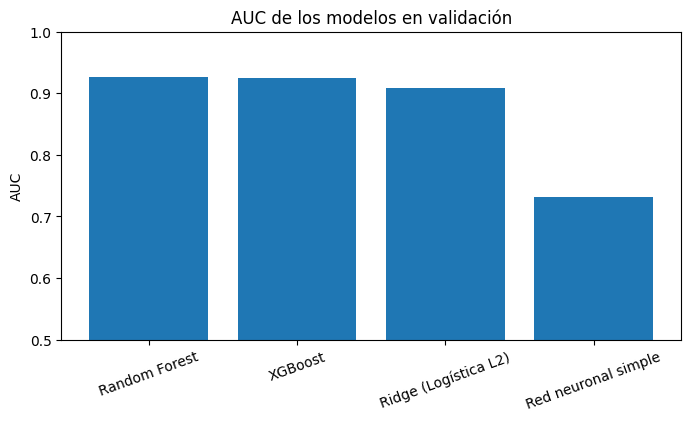

In [ ]:
# Gráfico comparativo de AUC en validación
plt.figure(figsize=(8, 4))
plt.bar(validacion["Modelo"], validacion["AUC"])
plt.title("AUC de los modelos en validación")
plt.ylabel("AUC")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=20)
plt.show()

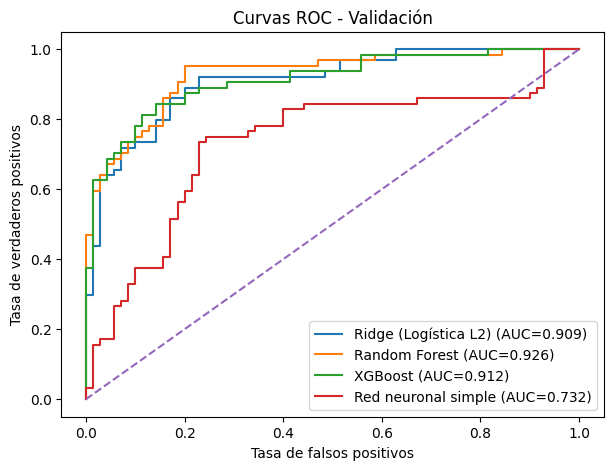

In [14]:
# Curvas ROC de los cuatro modelos en validación
plt.figure(figsize=(7, 5))

for nombre, modelo in modelos.items():
    prob = modelo.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, prob)
    auc = roc_auc_score(y_val, prob)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC - Validación")
plt.legend()
plt.show()

# Punto 3. Optimización de hiperparámetros

Se propone **GridSearchCV** como método de optimización.

GridSearchCV prueba diferentes combinaciones de hiperparámetros y utiliza validación cruzada para estimar cuál combinación presenta mejor desempeño. En este trabajo se aplica al Random Forest y se utiliza **AUC** como criterio de selección.

Se evalúan distintas cantidades de árboles, profundidades máximas y criterios mínimos para dividir o mantener observaciones en cada hoja.

In [15]:
modelo_rf_busqueda = Pipeline([
    ("preparacion", preprocesador),
    ("modelo", RandomForestClassifier(random_state=42))
])

parametros = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [4, 6, None],
    "modelo__min_samples_split": [2, 5],
    "modelo__min_samples_leaf": [1, 2]
}

busqueda = GridSearchCV(
    modelo_rf_busqueda,
    param_grid=parametros,
    scoring="roc_auc",
    cv=5,
    n_jobs=1
)

busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda.best_params_)
print("Mejor AUC promedio en validación cruzada:", round(busqueda.best_score_, 3))

Mejores hiperparámetros:
{'modelo__max_depth': None, 'modelo__min_samples_leaf': 2, 'modelo__min_samples_split': 5, 'modelo__n_estimators': 100}
Mejor AUC promedio en validación cruzada: 0.853


In [16]:
modelo_rf_optimizado = busqueda.best_estimator_

resultado_rf_optimizado = pd.DataFrame(
    evaluar_modelo(
        "Random Forest optimizado",
        modelo_rf_optimizado,
        X_train, y_train,
        X_val, y_val
    )
)

resultado_rf_optimizado.round(3)

,Modelo,Muestra,Accuracy,Precision,Recall,F1-Score,AUC,KS
0,Random Forest optimizado,Entrenamiento,0.905,0.93,0.805,0.863,0.975,0.826
1,Random Forest optimizado,Validación,0.821,0.90,0.703,0.789,0.921,0.704


## Conclusión de la optimización

GridSearchCV permitió encontrar una combinación de hiperparámetros con buen desempeño promedio en validación cruzada.

Sin embargo, al comparar directamente sobre la muestra de validación reservada, el Random Forest original mantiene una capacidad de discriminación igual o ligeramente superior. Por esta razón, **no se reemplaza automáticamente el modelo original solo porque fue optimizado**. La selección final se realiza considerando el desempeño real en validación y no únicamente el resultado de la búsqueda interna.

# Punto 4. Interpretación de resultados y selección del modelo final

Al comparar los cuatro modelos, Random Forest y XGBoost presentan los mejores resultados generales.

En esta ejecución, **Random Forest obtiene el AUC y KS más altos en validación**, lo que muestra una mejor capacidad para separar pasajeros sobrevivientes y no sobrevivientes.

Aunque otros modelos pueden presentar Accuracy similar o incluso ligeramente superior, el AUC se considera la métrica principal porque evalúa la discriminación del modelo a través de múltiples umbrales. Para este problema no se definió un costo específico para falsos positivos o falsos negativos, por lo que resulta adecuado utilizar una métrica global de discriminación.

Por lo tanto, se selecciona **Random Forest como modelo final**.

In [17]:
# Evaluación final en la muestra de test, que no se utilizó para seleccionar el modelo
pred_test = modelo_rf.predict(X_test)
prob_test = modelo_rf.predict_proba(X_test)[:, 1]

resultado_test = pd.DataFrame([{
    "Modelo final": "Random Forest",
    "Accuracy": accuracy_score(y_test, pred_test),
    "Precision": precision_score(y_test, pred_test, zero_division=0),
    "Recall": recall_score(y_test, pred_test, zero_division=0),
    "F1-Score": f1_score(y_test, pred_test, zero_division=0),
    "AUC": roc_auc_score(y_test, prob_test),
    "KS": calcular_ks(y_test, prob_test)
}])

resultado_test.round(3)

,Modelo final,Accuracy,Precision,Recall,F1-Score,AUC,KS
0,Random Forest,0.813,0.789,0.638,0.706,0.821,0.548


# Punto 5. Repositorio GitHub

El cuaderno de la Unidad 2 debe guardarse en el repositorio GitHub del proyecto para mantener trazabilidad y reproducibilidad.

**Repositorio:**  
https://github.com/242236/machine-learning-titanic

Para evitar publicar credenciales, no se incluye ningún token o contraseña dentro del notebook. El archivo puede guardarse en GitHub mediante la integración autenticada de Google Colab (**Archivo → Guardar una copia en GitHub**).

Los siguientes comandos muestran el flujo equivalente de control de versiones con Git:

In [18]:
# Ejemplo de comandos Git.
# Se dejan comentados para evitar ejecutarlos sin autenticación.

# !git clone https://github.com/242236/machine-learning-titanic.git
# !git add Evaluacion_Unidad_2_Machine_Learning_Titanic.ipynb
# !git commit -m "Evaluación Unidad 2 - modelos supervisados"
# !git push

# Conclusión

En esta evaluación se continuó el pipeline desarrollado con el dataset Titanic y se aplicaron cuatro modelos de aprendizaje supervisado para predecir la supervivencia de los pasajeros.

Se entrenó una regresión logística con penalización L2, Random Forest, XGBoost y una red neuronal simple. Los modelos fueron comparados en las muestras de entrenamiento y validación mediante Accuracy, Precision, Recall, F1-Score, AUC y KS.

La comparación mostró que los métodos ensamblados presentan un desempeño competitivo. Random Forest destacó por su capacidad de discriminación en validación, obteniendo los mejores valores de AUC y KS entre los modelos analizados, por lo que fue seleccionado como modelo final.

Además, se aplicó GridSearchCV como método de optimización de hiperparámetros. La búsqueda permitió evaluar distintas configuraciones mediante validación cruzada, aunque los resultados mostraron que una optimización no necesariamente implica una mejora en la muestra de validación reservada.

Finalmente, el modelo seleccionado fue evaluado en la muestra de test, manteniendo así la separación entre entrenamiento, validación y evaluación final. El desarrollo evidencia que la selección de un modelo debe considerar distintas métricas y priorizar la capacidad de generalización sobre el ajuste al conjunto de entrenamiento.

# Bibliografía

- Anderson, R. (2007). *The Credit Scoring Toolkit: Theory and Practice for Retail Credit Risk Management and Decision Automation*. Oxford University Press.
- Breiman, L. (2001). Random Forests. *Machine Learning, 45*(1), 5–32.
- Chen, T. & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794.
- Fawcett, T. (2006). An Introduction to ROC Analysis. *Pattern Recognition Letters, 27*(8), 861–874.
- Géron, A. (2019). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (2.ª ed.). O’Reilly Media.
- Goodfellow, I., Bengio, Y. & Courville, A. (2016). *Deep Learning*. MIT Press.
- Hastie, T., Tibshirani, R. & Friedman, J. (2017). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction* (2.ª ed.). Springer.
- James, G., Witten, D., Hastie, T. & Tibshirani, R. (2021). *An Introduction to Statistical Learning with Applications in R* (2.ª ed.). Springer.
- Material de estudio Unidad 2: *Aprendizaje supervisado*. Universidad Mayor.